# 01 · Data: download, checks and description

This notebook prepares the dataset for `02_train.ipynb` and describes it. It does not train anything.

**Data:** Bragagnolo, L., da Silva, R. V., Grzybowski, J. M. V. (2021). *Amazon and Atlantic Forest image datasets for semantic
segmentation*. Zenodo, [10.5281/zenodo.4498086](https://doi.org/10.5281/zenodo.4498086), CC-BY-4.0.

What the notebook does:
1. downloads the two RAR archives from Zenodo and checks their MD5 sums (skipped if the data is already there);
2. extracts them (skipped if already extracted);
3. builds a manifest with one row per image and saves it to `results/data_manifest.csv`;
4. describes the splits: number of images, forest fraction, Sentinel-2 tiles;
5. checks file pairs, shapes, data types and mask values;
6. checks with NDVI that mask value 1 means forest;
7. draws example images and compares the band distributions of the two biomes.

**Facts that differ from the Zenodo description.** The images are 4-band GeoTIFFs with 16-bit surface reflectance
(Sentinel-2 L2A, scaled by 10 000), not 8-bit images. Bands are 4, 3, 2, 8 = R, G, B, NIR, 512 × 512 px at 10 m. Masks are 0/1
(1 = forest). One later paper (Benvenuto et al., 2025) reads white as deforested; the NDVI check in section 6 shows that 1 is forest.

## 1. Settings

Paths are read from environment variables, like in `02_train.ipynb`:
- `DATA_ROOT`: folder with the extracted dataset (default `../data/bragagnolo`);
- `RAW_DIR`: folder for the downloaded archives (default `../data/raw`);
- `RESULTS_DIR`: where the manifest and figures are written (default `../results`).

In [1]:
import os, sys, hashlib, shutil, subprocess, time, urllib.request, urllib.parse
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from PIL import Image

DATA_ROOT = Path(os.environ.get("DATA_ROOT", "../data/bragagnolo"))
RAW_DIR = Path(os.environ.get("RAW_DIR", "../data/raw"))
RESULTS_DIR = Path(os.environ.get("RESULTS_DIR", "../results"))
FIGS = RESULTS_DIR / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

BIOMES = {"amazon": "AMAZON", "atlantic": "ATLANTIC FOREST"}
SPLITS = {"train": "Training", "val": "Validation", "test": "Test"}
BANDS = ["R", "G", "B", "NIR"]
ARCHIVES = {   # file name on Zenodo -> MD5 published on the record page
    "AMAZON.rar": "fd2a55b8437d65ac86e1a11161aeef98",
    "ATLANTIC FOREST.rar": "86ac319b7ff6738a96f555abb79fb445",
}
ZENODO = "https://zenodo.org/api/records/4498086/files/{}/content"
pd.set_option("display.width", 160)
rel = lambda p: os.path.relpath(p)   # paths are printed relative to the notebook folder
print("DATA_ROOT  ", rel(DATA_ROOT))
print("RESULTS_DIR", rel(RESULTS_DIR))

DATA_ROOT   ../../datasets/bragagnolo
RESULTS_DIR ../results


## 2. Download

The two archives are downloaded only if the extracted data is missing and the archive is not already in
`RAW_DIR`. Every archive is checked against the MD5 sum published on Zenodo.

In [2]:
def extracted(root=DATA_ROOT):
    """True if both biome folders with their three split folders exist."""
    return all((root / b / s).is_dir() for b in BIOMES.values() for s in SPLITS.values())

def md5(path, chunk=1 << 22):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

def download(name):
    """Download one archive with a simple progress line; a partial file is kept as .part and replaced at the end."""
    dst, part = RAW_DIR / name, RAW_DIR / (name + ".part")
    url = ZENODO.format(urllib.parse.quote(name))
    t0 = time.time()
    with urllib.request.urlopen(url) as r, open(part, "wb") as f:
        total, done = int(r.headers.get("Content-Length", 0)), 0
        while block := r.read(1 << 20):
            f.write(block); done += len(block)
            if total:
                print(f"\r  {name}: {done / 1e6:7.0f} / {total / 1e6:.0f} MB ({done / max(time.time() - t0, 1e-9) / 1e6:.1f} MB/s)",
                      end="", flush=True)
    print()
    part.rename(dst)

if extracted():
    print("Extracted data found in", rel(DATA_ROOT), "-> download skipped.")
else:
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    for name, expected in ARCHIVES.items():
        path = RAW_DIR / name
        if not path.exists():
            print("downloading", name)
            download(name)
        got = md5(path)
        if got != expected:
            raise RuntimeError(f"MD5 of {path} is {got}, expected {expected}. Delete the file and run this cell again.")
        print(f"{name}: MD5 ok")

Extracted data found in ../../datasets/bragagnolo -> download skipped.


## 3. Extraction

The archives use the **RAR 7 format** (compression method v6). Many common tools cannot read it: 7-Zip 26 and the `bsdtar` that
ships with macOS fail. Tools that work:
- **Linux:** RARLAB `unrar` 7.12 or newer (https://www.rarlab.com/rar/rarlinux-x64-712.tar.gz; `scripts/pod_setup.sh` uses it);
- **macOS:** `bsdtar` from Homebrew's `libarchive` (`brew install libarchive`, binary in `$(brew --prefix libarchive)/bin`) or
  `unrar` from RARLAB.

The cell tries `unrar` first and then the `bsdtar` binaries it can find, and checks after each attempt that the expected folders
exist.

In [3]:
def extractors():
    """Candidate commands, each a function archive -> argument list."""
    found = []
    if shutil.which("unrar"):
        found.append(("unrar", lambda a: ["unrar", "x", "-o+", "-idq", str(a), str(DATA_ROOT) + os.sep]))
    for b in ["/opt/homebrew/opt/libarchive/bin/bsdtar", "/usr/local/opt/libarchive/bin/bsdtar", shutil.which("bsdtar")]:
        if b and Path(b).exists() and b not in [f[0] for f in found]:
            found.append((b, lambda a, b=b: [b, "-xf", str(a), "-C", str(DATA_ROOT)]))
    return found

RAR7_HELP = """Could not extract the archives. They use the RAR 7 format (method v6), which 7-Zip and older bsdtar versions cannot read.
Install one of:
  - Linux: RARLAB unrar 7.12+   curl -LO https://www.rarlab.com/rar/rarlinux-x64-712.tar.gz && tar xzf rarlinux-x64-712.tar.gz
           (then put rar/unrar on the PATH)
  - macOS: brew install libarchive   (keg-only bsdtar in $(brew --prefix libarchive)/bin)   or RARLAB unrar for macOS
and run this cell again."""

if extracted():
    print("Extracted data found -> extraction skipped.")
else:
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    for name, biome_dir in zip(ARCHIVES, BIOMES.values()):
        if all((DATA_ROOT / biome_dir / s).is_dir() for s in SPLITS.values()):
            continue
        for tool, cmd in extractors():
            print(f"extracting {name} with {tool}")
            res = subprocess.run(cmd(RAW_DIR / name), capture_output=True, text=True)
            if res.returncode == 0 and all((DATA_ROOT / biome_dir / s).is_dir() for s in SPLITS.values()):
                break
            print("  failed:", (res.stderr or res.stdout).strip()[:300])
        else:
            raise RuntimeError(RAR7_HELP)
    assert extracted(), RAR7_HELP
print("dataset folders:", sorted(p.name for p in DATA_ROOT.iterdir() if p.is_dir()))

Extracted data found -> extraction skipped.
dataset folders: ['AMAZON', 'ATLANTIC FOREST']


## 4. Inventory

Folder names differ between splits (`image` / `images`, `label` / `mask` / `masks`). Images and masks are matched by file name,
with the same rule as `02_train.ipynb`. Other files (one `.aux.xml` file in `AMAZON/Validation/masks`) are ignored.

File names keep the Sentinel-2 product name and the position of the patch in the scene, for example
`S2A_MSIL2A_20200111T142701_N0213_R053_T20NQG_20200111T164651_01_06.tif`: satellite S2A, acquisition date 2020-01-11, relative
orbit R053, tile **T20NQG**, patch row 01 and column 06.

For each image the manifest stores: biome, split, file, satellite, date, tile, patch row and column, the patch centre in the
tile's UTM coordinates, size, data type, forest fraction, per-band mean, and the mean NDVI of forest and non-forest pixels.
Reading all 1,224 images and their masks takes under a minute on a laptop SSD.

In [4]:
def split_dirs(biome, split):
    root = DATA_ROOT / BIOMES[biome] / SPLITS[split]
    img_dir = next(d for d in root.iterdir() if d.is_dir() and d.name.lower().startswith("image"))
    msk_dir = next(d for d in root.iterdir() if d.is_dir() and not d.name.lower().startswith("image"))
    return img_dir, msk_dir

def parse_name(stem):
    p = stem.split("_")   # S2A MSIL2A 20200111T142701 N0213 R053 T20NQG 20200111T164651 01 06
    return dict(satellite=p[0], date=pd.Timestamp(p[2][:8]).date(), orbit=p[4], tile=p[5], patch_row=int(p[7]), patch_col=int(p[8]))

HIST_BIN, HIST_MAX = 25, 10000            # reflectance histogram: bins of 25 up to 10 000 (larger values go into the last bin)
NDVI_BINS = np.linspace(-1, 1, 201)
hist = {b: np.zeros((4, HIST_MAX // HIST_BIN + 1), np.int64) for b in BIOMES}
ndvi_hist = {(b, c): np.zeros(len(NDVI_BINS) - 1, np.int64) for b in BIOMES for c in (0, 1)}

rows, unmatched = [], []
t0 = time.time()
for biome in BIOMES:
    for split in SPLITS:
        img_dir, msk_dir = split_dirs(biome, split)
        imgs = {p.stem: p for p in img_dir.iterdir() if p.suffix.lower() in (".tif", ".tiff")}
        msks = {p.stem: p for p in msk_dir.iterdir() if p.suffix.lower() in (".tif", ".tiff")}
        unmatched += [(biome, split, "image without mask", s) for s in sorted(imgs.keys() - msks.keys())]
        unmatched += [(biome, split, "mask without image", s) for s in sorted(msks.keys() - imgs.keys())]
        for stem in sorted(imgs.keys() & msks.keys()):
            with rasterio.open(imgs[stem]) as r:
                x, img_transform, crs, img_dtype = r.read(), r.transform, r.crs, r.dtypes[0]
            with rasterio.open(msks[stem]) as r:
                mask_transform = r.transform
            m = np.array(Image.open(msks[stem]))          # read like 02_train.ipynb does
            forest = m > 0
            red, nir = x[0].astype(np.float32), x[3].astype(np.float32)
            ndvi = (nir - red) / np.maximum(nir + red, 1)
            for c in (0, 1):
                ndvi_hist[(biome, c)] += np.histogram(ndvi[forest == c], NDVI_BINS)[0]
            for k in range(4):
                hist[biome][k] += np.bincount(np.minimum(x[k] // HIST_BIN, HIST_MAX // HIST_BIN).ravel(), minlength=hist[biome].shape[1])
            cx, cy = img_transform * (x.shape[2] / 2, x.shape[1] / 2)
            rows.append(dict(biome=biome, split=split, file=stem + imgs[stem].suffix, **parse_name(stem),
                             crs=crs.to_string(), x_center=cx, y_center=cy, height=x.shape[1], width=x.shape[2], bands=x.shape[0],
                             image_dtype=img_dtype, mask_dtype=str(m.dtype), mask_values=",".join(map(str, np.unique(m))),
                             same_georef=img_transform == mask_transform, zero_fraction=float((x == 0).all(0).mean()),
                             forest_fraction=float(forest.mean()),
                             **{f"mean_{b}": float(x[k].mean()) for k, b in enumerate(BANDS)},
                             ndvi_forest=float(ndvi[forest].mean()) if forest.any() else np.nan,
                             ndvi_nonforest=float(ndvi[~forest].mean()) if (~forest).any() else np.nan))
manifest = pd.DataFrame(rows)
manifest.to_csv(RESULTS_DIR / "data_manifest.csv", index=False)
print(f"{len(manifest)} images read in {time.time() - t0:.0f} s -> {rel(RESULTS_DIR / 'data_manifest.csv')}")
manifest.head(3).T

1224 images read in 24 s -> ../results/data_manifest.csv


,0,1,2
biome,amazon,amazon,amazon
split,train,train,train
file,S2A_MSIL2A_20200111T142701_N0213_R053_T20NQG_2...,S2A_MSIL2A_20200111T142701_N0213_R053_T20NQG_2...,S2A_MSIL2A_20200111T142701_N0213_R053_T20NQG_2...
satellite,S2A,S2A,S2A
date,2020-01-11,2020-01-11,2020-01-11
orbit,R053,R053,R053
tile,T20NQG,T20NQG,T20NQG
patch_row,1,1,2
patch_col,7,13,3
crs,EPSG:32620,EPSG:32620,EPSG:32620


## 5. The splits

### 5.1 Images per split and biome

Expected (from the dataset description): Amazon 499 / 100 / 20 and Atlantic Forest 485 / 100 / 20 (train / val / test).
In this project the *whole other biome* (all 605 images of it) is also used as a transfer test set.

In [5]:
counts = manifest.pivot_table(index="biome", columns="split", values="file", aggfunc="count")[list(SPLITS)]
counts["total"] = counts.sum(axis=1)
counts

split,train,val,test,total
biome,,,,
amazon,499,100,20,619
atlantic,485,100,20,605


### 5.2 Forest fraction

Share of forest pixels (all images have the same size, so this is also the mean of the per-image fractions). The Amazon is about
half forest; the Atlantic Forest about one third. A model that moves from one biome to the other also meets a different class
balance.

In [6]:
frac = manifest.pivot_table(index="biome", columns="split", values="forest_fraction", aggfunc="mean")[list(SPLITS)]
frac["all"] = manifest.groupby("biome")["forest_fraction"].mean()
frac.round(3)

split,train,val,test,all
biome,,,,
amazon,0.529,0.522,0.502,0.527
atlantic,0.330,0.338,0.315,0.331


In [7]:
manifest.groupby(["biome", "split"])["forest_fraction"].describe(percentiles=[0.1, 0.5, 0.9]).round(3)

count   mean    std    min    10%    50%    90%    max
biome    split                                                        
amazon   test    20.0  0.502  0.264  0.000  0.161  0.550  0.820  0.927
         train  499.0  0.529  0.310  0.017  0.155  0.465  0.973  1.000
         val    100.0  0.522  0.316  0.000  0.152  0.420  0.963  1.000
atlantic test    20.0  0.315  0.153  0.031  0.146  0.298  0.483  0.557
         train  485.0  0.330  0.182  0.009  0.136  0.285  0.601  0.953
         val    100.0  0.338  0.199  0.018  0.128  0.288  0.599  0.953

### 5.3 Sentinel-2 tiles and dates

Each biome comes from only a few Sentinel-2 tiles (3 to 4), some of them with two acquisition dates. The table counts images per
tile, date and split: **the same tiles and dates appear in train, validation and test**. The patches of the three splits are cut
from the same scenes.

In [8]:
tiles = manifest.pivot_table(index=["biome", "tile", "date"], columns="split", values="file", aggfunc="count", fill_value=0)[list(SPLITS)]
tiles["total"] = tiles.sum(axis=1)
tiles

split                       train  val  test  total
biome    tile   date                               
amazon   T20LMP 2020-08-18    222   48     7    277
         T20LQN 2020-02-02     29    9     2     40
                2020-02-17    122   23     7    152
         T20NQG 2020-01-11     93   13     4    110
         T21LUH 2020-01-15     33    7     0     40
atlantic T22JCS 2019-11-29    130   29     3    162
                2020-08-10     64   13     2     79
         T23KQV 2019-11-05     72   12     5     89
                2020-06-12    143   30     6    179
         T24LVH 2019-07-15     76   16     4     96

In [9]:
print("tiles per biome and split:")
print(manifest.groupby(["biome", "split"])["tile"].nunique().unstack()[list(SPLITS)])
print("\ntiles shared between biomes:", set(manifest.query("biome == 'amazon'").tile) & set(manifest.query("biome == 'atlantic'").tile) or "none")

tiles per biome and split:
split     train  val  test
biome                     
amazon        4    4     3
atlantic      3    3     3

tiles shared between biomes: none


**How close are the splits?** For each validation and test patch we measure the distance from its centre to the nearest training
patch centre of the same tile. A patch is 512 px × 10 m = 5.12 km wide, so a distance of 5.12 km means the patches touch.
If most test patches have a training neighbour at about 5 km, in-biome test scores describe nearby, very similar land, and are
optimistic. Cross-biome evaluation does not have this problem: the two biomes share no tile.

In [10]:
near = []
for (biome, tile), g in manifest.groupby(["biome", "tile"]):
    train_xy = g.loc[g.split == "train", ["x_center", "y_center"]].to_numpy()
    for _, r in g[g.split != "train"].iterrows():
        d = np.sqrt(((train_xy - [r.x_center, r.y_center]) ** 2).sum(1)).min() / 1000 if len(train_xy) else np.nan
        near.append(dict(biome=biome, split=r.split, tile=tile, km_to_nearest_train=d))
near = pd.DataFrame(near)
near.groupby(["biome", "split"])["km_to_nearest_train"].describe().round(2)

count  mean   std   min   25%   50%   75%    max
biome    split                                                  
amazon   test    20.0  7.72  6.38  5.12  5.12  5.12  5.65  26.11
         val    100.0  5.85  2.75  0.00  5.12  5.12  5.12  25.60
atlantic test    20.0  4.10  2.68  0.00  3.84  5.12  5.12  10.24
         val    100.0  4.26  3.49  0.00  0.00  5.12  5.12  16.19

A distance of 0 km means the patch covers **exactly the same ground as a training patch**, taken on another date (tiles with two
dates). The next cell counts, for each validation and test patch, the largest area it shares with any training patch of the same
tile, and whether that training patch has the same date. The same is counted inside the training split.

In [11]:
S = 512 * 10   # patch width in metres
ov = []
for (biome, tile), g in manifest.groupby(["biome", "tile"]):
    tr = g[g.split == "train"]
    for _, r in g[g.split != "train"].iterrows():
        share = (np.clip(S - (tr.x_center - r.x_center).abs(), 0, None) * np.clip(S - (tr.y_center - r.y_center).abs(), 0, None)) / S**2
        best = share.idxmax() if len(share) else None
        ov.append(dict(biome=biome, split=r.split, shared_area=share.max() if len(share) else 0.0,
                       same_date=bool(best is not None and share.max() > 0 and tr.loc[best, "date"] == r.date)))
ov = pd.DataFrame(ov)
overlap = ov.groupby(["biome", "split"]).agg(
    images=("shared_area", "size"),
    overlap_any=("shared_area", lambda v: int((v > 0).sum())),
    same_ground=("shared_area", lambda v: int((v > 0.999).sum())),
    overlap_same_date=("same_date", "sum"))
overlap["train_same_ground_twice"] = [int(manifest.query("biome == @b and split == 'train'").duplicated(["tile", "x_center", "y_center"]).sum())
                                      for b, _ in overlap.index]
overlap

images  overlap_any  same_ground  overlap_same_date  train_same_ground_twice
biome    split                                                                              
amazon   test       20            0            0                  0                        5
         val       100            1            1                  0                        5
atlantic test       20            5            5                  0                       60
         val       100           29           29                  0                       60

## 6. Checks

Every image must have a mask; images must be 4 × 512 × 512 `uint16`; masks 512 × 512 `uint8` with values in {0, 1}; image and
mask must have the same georeference; no file may appear in two splits. Pixels where all four bands are 0 would be missing data;
a handful of such pixels is harmless, so the check only fails above 1 % of an image.

In [12]:
checks = {
    "every image has a mask and every mask an image": len(unmatched) == 0,
    "image shape 4 x 512 x 512": ((manifest.bands == 4) & (manifest.height == 512) & (manifest.width == 512)).all(),
    "image dtype uint16": (manifest.image_dtype == "uint16").all(),
    "mask dtype uint8": (manifest.mask_dtype == "uint8").all(),
    "mask values within {0, 1}": manifest.mask_values.isin(["0", "1", "0,1"]).all(),
    "image and mask have the same georeference": manifest.same_georef.all(),
    "no file in two splits": not manifest.duplicated(["biome", "file"]).any(),
    "no patch with more than 1 % no-data pixels (all bands 0)": (manifest.zero_fraction <= 0.01).all(),
}
for k, v in checks.items():
    print(f"{'OK  ' if v else 'FAIL'} {k}")
print("\nunmatched files:", unmatched or "none")
nz = manifest[manifest.zero_fraction > 0]
print(f"images with any all-zero pixel: {len(nz)} (largest share {nz.zero_fraction.max() if len(nz) else 0:.5f}, i.e. a few pixels)")
print("mask values seen:", manifest.mask_values.value_counts().to_dict())
print("images with no forest:", (manifest.forest_fraction == 0).sum(), "| images with only forest:", (manifest.forest_fraction == 1).sum())
print(f"reflectance range: max band means {manifest[[f'mean_{b}' for b in BANDS]].max().round(0).to_dict()}")
assert all(checks.values()), "some checks failed"

OK   every image has a mask and every mask an image
OK   image shape 4 x 512 x 512
OK   image dtype uint16
OK   mask dtype uint8
OK   mask values within {0, 1}
OK   image and mask have the same georeference
OK   no file in two splits
OK   no patch with more than 1 % no-data pixels (all bands 0)

unmatched files: none
images with any all-zero pixel: 5 (largest share 0.00014, i.e. a few pixels)
mask values seen: {'0,1': 1221, '0': 2, '1': 1}
images with no forest: 2 | images with only forest: 1
reflectance range: max band means {'mean_R': 2874.0, 'mean_G': 3067.0, 'mean_B': 3142.0, 'mean_NIR': 4687.0}


## 7. Does mask value 1 mean forest? An NDVI check

The Zenodo description says white (1) is forest; one later paper uses the opposite reading. NDVI = (NIR − R) / (NIR + R) is high
for dense vegetation (typically > 0.7 for closed tropical forest) and lower for pasture, crops, bare soil and water. If 1 is
forest, pixels with mask 1 must have clearly higher NDVI than pixels with mask 0, in both biomes.

In [13]:
ndvi_tab = pd.DataFrame([dict(biome=b, mask=c, label="forest" if c else "non-forest", pixels=h.sum(),
                              mean_ndvi=(h * (NDVI_BINS[:-1] + NDVI_BINS[1:]) / 2).sum() / h.sum())
                         for (b, c), h in ndvi_hist.items()])
print(ndvi_tab.round(3).to_string(index=False))
per_img = manifest.dropna(subset=["ndvi_forest", "ndvi_nonforest"])
print(f"\nimages where forest pixels have higher mean NDVI than non-forest pixels: "
      f"{(per_img.ndvi_forest > per_img.ndvi_nonforest).sum()} of {len(per_img)} (images with both classes)")

   biome  mask      label    pixels  mean_ndvi
  amazon     0 non-forest  76803712      0.479
  amazon     1     forest  85463424      0.843
atlantic     0 non-forest 106083611      0.593
atlantic     1     forest  52513509      0.852

images where forest pixels have higher mean NDVI than non-forest pixels: 1220 of 1221 (images with both classes)


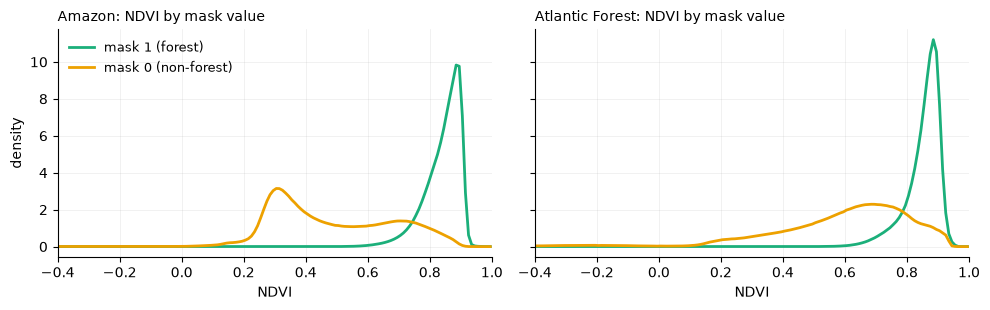

In [14]:
COL = {"forest": "#1baf7a", "non-forest": "#eda100"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
centres = (NDVI_BINS[:-1] + NDVI_BINS[1:]) / 2
for ax, b in zip(axes, BIOMES):
    for c, lab in [(1, "forest"), (0, "non-forest")]:
        h = ndvi_hist[(b, c)]
        ax.plot(centres, h / h.sum() / np.diff(NDVI_BINS), color=COL[lab], lw=2, label=f"mask {c} ({lab})")
    ax.set_title(f"{BIOMES[b].title()}: NDVI by mask value", loc="left", fontsize=10)
    ax.set_xlabel("NDVI"); ax.set_xlim(-0.4, 1)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5)
axes[0].set_ylabel("density"); axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "fig0_ndvi.png", dpi=200); plt.show()

## 8. Figures

### 8.1 Example images

Four test images per biome, chosen with low, medium and high forest fraction. Top row: true colour (R, G, B) with a 2–98 %
percentile stretch per image. Bottom row: the same image with the forest mask (value 1) in green.
Note that clouds are labelled non-forest: the Amazon test set contains an image covered by cloud with 0 % forest.

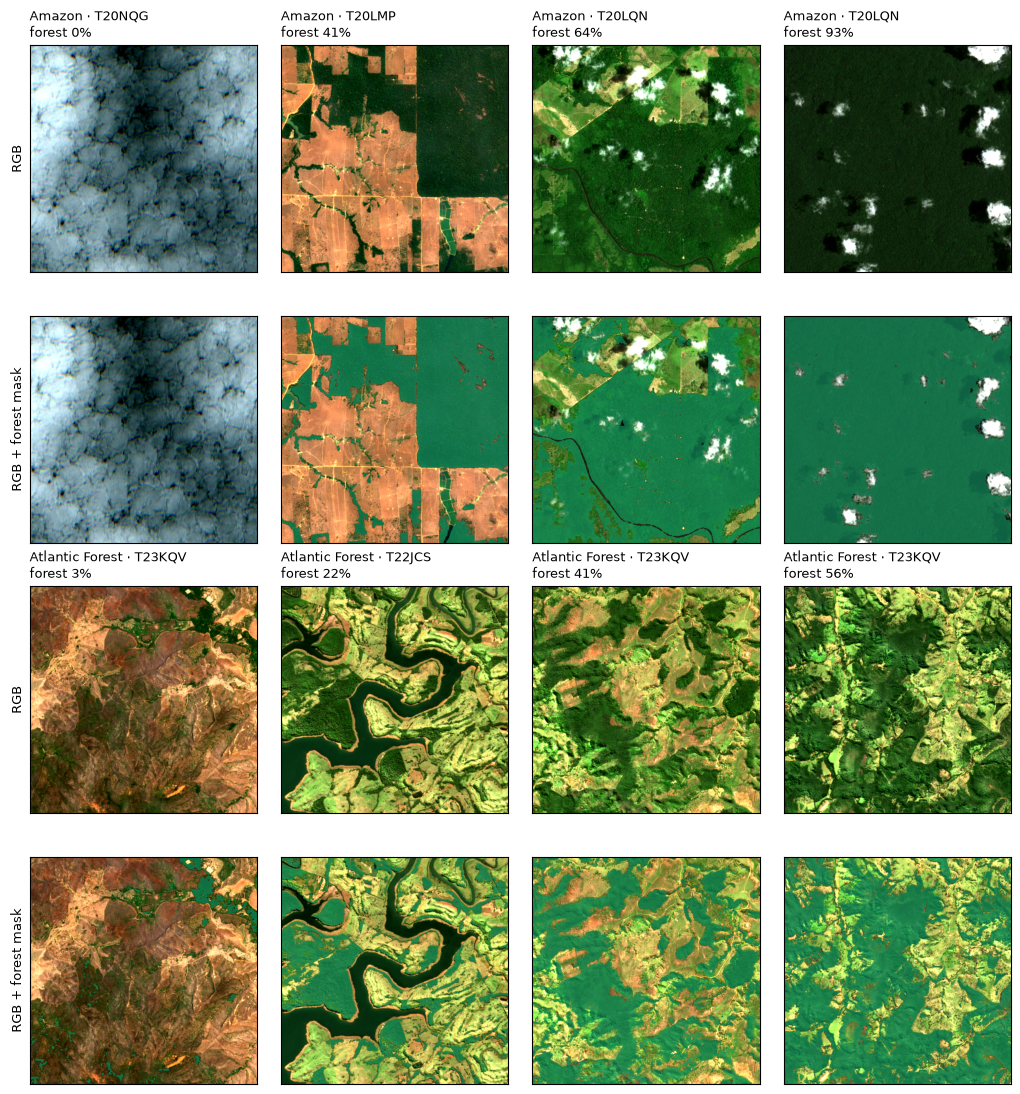

In [15]:
def rgb(x):
    """Percentile-stretched RGB (bands 0, 1, 2) for display."""
    v = x[:3].astype(np.float32)
    lo, hi = np.percentile(v, [2, 98])
    return np.clip((v - lo) / max(hi - lo, 1), 0, 1).transpose(1, 2, 0)

def load(biome, split, file):
    img_dir, msk_dir = split_dirs(biome, split)
    with rasterio.open(img_dir / file) as r:
        x = r.read()
    return x, np.array(Image.open(msk_dir / file)) > 0

n = 4
fig, axes = plt.subplots(4, n, figsize=(2.6 * n, 2.75 * 4))
green = np.array([0x1b, 0xaf, 0x7a]) / 255
for bi, b in enumerate(BIOMES):
    t = manifest.query("biome == @b and split == 'test'").sort_values("forest_fraction")
    picks = t.iloc[np.linspace(0, len(t) - 1, n).round().astype(int)]
    for j, (_, r) in enumerate(picks.iterrows()):
        x, m = load(b, "test", r.file)
        im = rgb(x)
        over = im.copy(); over[m] = 0.45 * over[m] + 0.55 * green
        axes[2 * bi, j].imshow(im); axes[2 * bi + 1, j].imshow(over)
        axes[2 * bi, j].set_title(f"{BIOMES[b].title()} · {r.tile}\nforest {r.forest_fraction:.0%}", fontsize=9, loc="left")
    axes[2 * bi, 0].set_ylabel("RGB", fontsize=9); axes[2 * bi + 1, 0].set_ylabel("RGB + forest mask", fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); fig.savefig(FIGS / "fig0_examples.png", dpi=110); plt.show()

### 8.2 Band distributions: the domain shift between biomes

Distribution of reflectance values per band over all images of each biome (all splits). The two biomes differ in every band.
This difference is one reason why models trained on one biome lose accuracy on the other. In `02_train.ipynb` the input is
standardized with the training biome's statistics only, so the shift is still there when a model sees the other biome.

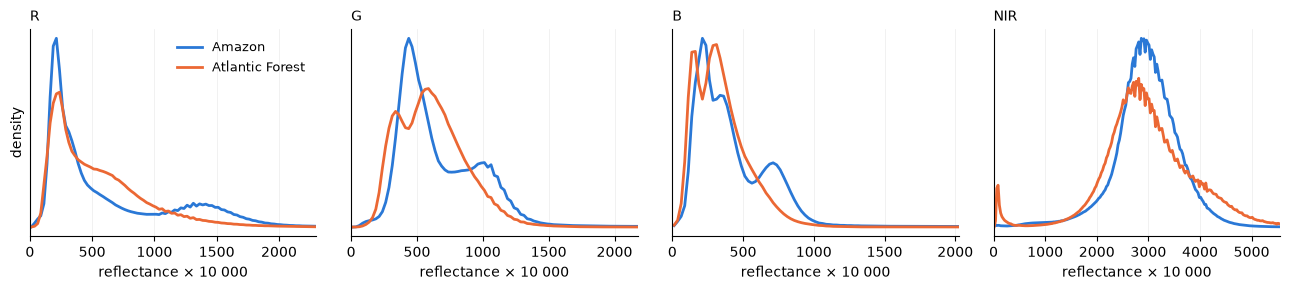

In [16]:
BIOME_COL = {"amazon": "#2a78d6", "atlantic": "#eb6834"}
edges = np.arange(hist["amazon"].shape[1] + 1) * HIST_BIN
fig, axes = plt.subplots(1, 4, figsize=(13, 3.0))
for k, (ax, band) in enumerate(zip(axes, BANDS)):
    for b in BIOMES:
        h = hist[b][k][:-1]                                   # last bin collects values >= 10 000
        ax.plot(edges[:-2] + HIST_BIN / 2, h / hist[b][k].sum() / HIST_BIN, color=BIOME_COL[b], lw=2, label=BIOMES[b].title())
    both = hist["amazon"][k] + hist["atlantic"][k]
    ax.set_xlim(0, edges[np.searchsorted(np.cumsum(both) / both.sum(), 0.995)])
    ax.set_title(band, loc="left", fontsize=10); ax.set_xlabel("reflectance × 10 000")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5); ax.set_yticks([])
axes[0].set_ylabel("density"); axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "fig0_band_hist.png", dpi=200); plt.show()

In [17]:
band_stats = manifest.groupby("biome")[[f"mean_{b}" for b in BANDS]].mean().round(0)
band_stats.loc["atlantic / amazon"] = (band_stats.loc["atlantic"] / band_stats.loc["amazon"]).round(2)
band_stats

,mean_R,mean_G,mean_B,mean_NIR
biome,,,,
amazon,629.00,691.00,444.00,2964.00
atlantic,537.00,615.00,343.00,3005.00
atlantic / amazon,0.85,0.89,0.77,1.01


## 9. Summary

- Counts match the dataset description: Amazon 499 / 100 / 20, Atlantic Forest 485 / 100 / 20.
- Images are 16-bit reflectance (not 8-bit), bands R, G, B, NIR; masks are 0/1 and 1 is forest (NDVI check).
- Each biome comes from a few Sentinel-2 tiles, and train, validation and test patches are cut from the same scenes, mostly next
  to each other. Some validation and test patches (Atlantic Forest: 5 of 20 test, 29 of 100 validation; Amazon: 1 validation)
  cover exactly the same ground as a training patch, imaged on another date. In-biome test scores are therefore optimistic. The two
  biomes share no tile, so cross-biome scores are a cleaner test of generalization.
- Forest fraction and band distributions differ between the biomes (class balance and domain shift).

Next: `02_train.ipynb`.